# Lens Design Challenge — Polychromatic RMS spot minimisation

**Author:** Lorenzo Fratini

**Design:** Double Gauss, 6 elements in 4 groups (two cemented doublets) — glasses N-SSK2, N-SK2, F5, N-SK16 — spherical surfaces only, stop in the central air space.

| Rule | Requirement |
|---|---|
| Object distance | Infinity |
| EFL | 50 mm ± 1 % |
| F-number | f/4 ± 2 % |
| Elements | 3 – 6, spherical only, catalog glasses |
| Stop | inside the optical system |
| BFD | ≥ 10 mm |
| Total track | ≤ 80 mm |
| Fields (semi-field) | 0°, 7°, 10°, 12°, 14° |
| Wavelengths | 0.486, 0.588, 0.656 µm, equal weights |
| Distortion | ≤ 2 % at every field |
| Center / edge thickness | ≥ 2 mm / ≥ 1 mm per element |

**Merit:** Σ (polychromatic RMS spot)² over the 5 fields **+ P**, where P = Σ (W·vᵢ)² has one term per rule (vᵢ = normalised violation, 0 when the rule is met).
The polychromatic RMS spot uses the rays of all three wavelengths about their **common centroid**, so lateral colour is included.

In [ ]:
# Install Optiland (needed on Google Colab)
%pip install -q optiland

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import optiland
from optiland.optic import Optic
from optiland.distribution import HexagonalDistribution
from optiland.optimization.operand.lens import LensOperand
from optiland.analysis import SpotDiagram, RmsSpotSizeVsField, Distortion



Optiland version: 0.6.2


## 1. Specification

In [3]:
EFL_TARGET, EFL_TOL = 50.0, 0.01      # +-1 %
FNO_TARGET, FNO_TOL = 4.0, 0.02       # +-2 %
BFD_MIN, TTL_MAX = 10.0, 80.0         # mm
DIST_MAX = 2.0                        # %
CT_MIN, ET_MIN = 2.0, 1.0             # mm
FIELDS_DEG = [0.0, 7.0, 10.0, 12.0, 14.0]
WAVELENGTHS = [0.486, 0.588, 0.656]   # um, equal weights
PRIMARY_WL = 0.588
PENALTY_WEIGHT = 1.0

## 2. Final design

Optimized lens (obtained with the optimisation in Section 6, starting from Optiland's Double Gauss).

In [4]:
def build_final_design():
    lens = Optic(name="Double Gauss N-SSK2 / N-SK2 / F5 / N-SK16")
    g = lambda name: (name, "schott")
    lens.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
    lens.surfaces.add(index=1, radius=28.173670624057166, thickness=4.341747993184715, material=g("N-SSK2"))
    lens.surfaces.add(index=2, radius=75.83366032379183, thickness=0.5121738503665352)
    lens.surfaces.add(index=3, radius=18.8994515253172, thickness=6.175108543587461, material=g("N-SK2"))
    lens.surfaces.add(index=4, radius=np.inf, thickness=2.000567059870285, material=g("F5"))  # cemented, flat
    lens.surfaces.add(index=5, radius=12.053095239249489, thickness=7.909235116323462)
    lens.surfaces.add(index=6, radius=np.inf, thickness=6.624002323986925, is_stop=True)
    lens.surfaces.add(index=7, radius=-14.18178760046791, thickness=2.0001415318414324, material=g("F5"))
    lens.surfaces.add(index=8, radius=195.40536993028365, thickness=5.460539552636167, material=g("N-SK16"))  # cemented
    lens.surfaces.add(index=9, radius=-18.946986350104588, thickness=0.5321204177172731)
    lens.surfaces.add(index=10, radius=88.1485003398973, thickness=3.432571586944441, material=g("N-SK16"))
    lens.surfaces.add(index=11, radius=-39.732494020726406, thickness=31.13096930207179)
    lens.surfaces.add(index=12)

    lens.set_aperture(aperture_type="imageFNO", value=FNO_TARGET)
    lens.fields.set_type("angle")
    for fy in FIELDS_DEG:
        lens.fields.add(y=fy)
    for wl in WAVELENGTHS:
        lens.wavelengths.add(value=wl, is_primary=(wl == PRIMARY_WL))
    return lens


lens = build_final_design()
lens.info()

╒════╤═══════════════╤═══════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment   │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪═══════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │           │ inf      │  inf        │ Air        │       0 │        13.3994  │
│  1 │ Standard      │           │  28.1737 │    4.34175  │ N-SSK2     │       0 │        13.3994  │
│  2 │ Standard      │           │  75.8337 │    0.512174 │ Air        │       0 │        11.94    │
│  3 │ Standard      │           │  18.8995 │    6.17511  │ N-SK2      │       0 │        11.7109  │
│  4 │ Planar        │           │ inf      │    2.00057  │ F5         │       0 │         8.54667 │
│  5 │ Standard      │           │  12.0531 │    7.90924  │ Air        │       0 │         7.51899 │
│  6 │ Stop - Planar │           │ inf      │    6.624    │ Air        │       0 │         

## 3. Metrics and penalty term P

In [5]:
def thicknesses(optic):
    z = np.asarray(optic.surfaces.positions).ravel()
    return np.diff(z[1:])                      # thickness after surface 1, 2, ...


def elements(optic):
    # (front, back) surface indices of every glass element
    out = []
    for i in range(1, optic.surfaces.num_surfaces - 1):
        if float(np.squeeze(optic.surfaces[i].material_post.n(PRIMARY_WL))) > 1.01:
            out.append((i, i + 1))
    return out


def spot_sizes(optic, rings=16):
    # Polychromatic RMS spot radius (mm) per field, about the common centroid of the 3 wavelengths
    dist = HexagonalDistribution()
    dist.generate_points(rings)
    px, py = np.asarray(dist.x), np.asarray(dist.y)
    nf, npup = len(FIELDS_DEG), len(px)
    Hy = np.repeat(np.array(FIELDS_DEG) / FIELDS_DEG[-1], npup)
    Px, Py = np.tile(px, nf), np.tile(py, nf)
    xs, ys = [], []
    for wl in WAVELENGTHS:
        rays = optic.trace_generic(np.zeros_like(Hy), Hy, Px, Py, wl)
        xs.append(np.asarray(rays.x).reshape(nf, npup))
        ys.append(np.asarray(rays.y).reshape(nf, npup))
    x, y = np.concatenate(xs, axis=1), np.concatenate(ys, axis=1)
    rms = np.sqrt(np.mean((x - x.mean(1, keepdims=True)) ** 2 + (y - y.mean(1, keepdims=True)) ** 2, axis=1))
    return np.where(np.isfinite(rms), rms, 10.0)


def distortions(optic, near_axis_deg=0.1):
    # Real chief-ray f-tan distortion (%); reference scale from a near-axis real chief ray
    angles = np.array([near_axis_deg] + FIELDS_DEG[1:])
    Hy = angles / FIELDS_DEG[-1]
    zeros = np.zeros_like(Hy)
    y = np.asarray(optic.trace_generic(zeros, Hy, zeros, zeros, PRIMARY_WL).y)
    tan = np.tan(np.radians(angles))
    scale = y[0] / tan[0]
    return [0.0] + list(100.0 * (y[1:] - scale * tan[1:]) / (scale * tan[1:]))


def system_values(optic):
    # Semi-apertures = |marginal| + |chief| paraxial ray height (Optiland convention);
    # refresh them so the edge thickness is measured on the current lens.
    optic.updater.update_paraxial()
    t = thicknesses(optic)
    efl = float(optic.paraxial.f2())
    elems = elements(optic)
    stop = optic.surfaces.stop_index
    return {
        "efl": efl,
        "fno": efl / float(optic.paraxial.EPD()),
        "bfd": float(t[-1]),
        "ttl": float(t.sum()),
        "dist": distortions(optic),
        "ct": [float(t[a - 1]) for a, _ in elems],
        "et": [float(np.squeeze(LensOperand.edge_thickness(optic, a))) for a, _ in elems],
        "n_elements": len(elems),
        "stop_inside": elems[0][0] <= stop <= elems[-1][1],
    }


def violations(optic, margin=None):
    # Normalised violation of every rule (0 = rule satisfied). `margin` tightens the limits during optimisation.
    m = margin or {"efl": 0, "fno": 0, "bfd": 0, "ttl": 0, "dist": 0, "et": 0}
    v = system_values(optic)
    return {
        "EFL": max(0.0, abs(v["efl"] / EFL_TARGET - 1) - (EFL_TOL - m["efl"])) / EFL_TOL,
        "F-number": max(0.0, abs(v["fno"] / FNO_TARGET - 1) - (FNO_TOL - m["fno"])) / FNO_TOL,
        "BFD": max(0.0, BFD_MIN + m["bfd"] - v["bfd"]) / BFD_MIN,
        "TTL": max(0.0, v["ttl"] - (TTL_MAX - m["ttl"])) / TTL_MAX,
        "Distortion": sum(max(0.0, abs(d) - (DIST_MAX - m["dist"])) for d in v["dist"]) / DIST_MAX,
        "Center thickness": sum(max(0.0, CT_MIN - t) for t in v["ct"]) / CT_MIN,
        "Edge thickness": sum(max(0.0, ET_MIN + m["et"] - t) for t in v["et"]) / ET_MIN,
        "Elements (3-6)": float(not 3 <= v["n_elements"] <= 6),
        "Stop inside system": float(not v["stop_inside"]),
    }


def penalty(optic, margin=None):
    # P = sum_i (W * v_i)^2  -- penalises every constraint violation
    return sum((PENALTY_WEIGHT * x) ** 2 for x in violations(optic, margin).values())

## 4. Results

In [6]:
spots_um = spot_sizes(lens) * 1e3
v = system_values(lens)

results = pd.DataFrame({
    "Field [deg]": FIELDS_DEG,
    "Polychromatic RMS spot [um]": spots_um,
    "Distortion [%]": v["dist"],
})
display(results.style.format({"Polychromatic RMS spot [um]": "{:.3f}", "Distortion [%]": "{:.3f}"}).hide(axis="index"))
print(f"Mean polychromatic RMS spot over the 5 fields: {spots_um.mean():.3f} um")

Field [deg],Polychromatic RMS spot [um],Distortion [%]
0.000000,5.741,0.000
7.000000,4.402,-0.250
10.000000,4.559,-0.531
12.000000,5.575,-0.792
14.000000,7.337,-1.124


Mean polychromatic RMS spot over the 5 fields: 5.523 um


In [7]:
max_dist = max(abs(d) for d in v["dist"])
checks = pd.DataFrame([
    ("EFL [mm]",                  f"{v['efl']:.3f}",      "49.5 - 50.5",  abs(v["efl"] / EFL_TARGET - 1) <= EFL_TOL),
    ("F-number",                  f"{v['fno']:.3f}",      "3.92 - 4.08",  abs(v["fno"] / FNO_TARGET - 1) <= FNO_TOL),
    ("Elements",                  f"{v['n_elements']}",   "3 - 6",        3 <= v["n_elements"] <= 6),
    ("Stop inside system",        f"{v['stop_inside']}",  "True",         v["stop_inside"]),
    ("BFD [mm]",                  f"{v['bfd']:.3f}",      ">= 10",        v["bfd"] >= BFD_MIN),
    ("Total track [mm]",          f"{v['ttl']:.3f}",      "<= 80",        v["ttl"] <= TTL_MAX),
    ("Max |distortion| [%]",      f"{max_dist:.3f}",      "<= 2",         max_dist <= DIST_MAX),
    ("Min center thickness [mm]", f"{min(v['ct']):.3f}",  ">= 2",         min(v["ct"]) >= CT_MIN),
    ("Min edge thickness [mm]",   f"{min(v['et']):.3f}",  ">= 1",         min(v["et"]) >= ET_MIN),
], columns=["Rule", "Value", "Limit", "OK"])
display(checks.style.hide(axis="index"))

P = penalty(lens)
score = float(np.sum((spots_um * 1e-3) ** 2)) + P
print(f"Penalty P = {P:.3e}")
print(f"Score = sum(RMS^2) + P = {score:.4e} mm^2")

Rule,Value,Limit,OK
EFL [mm],50.002,49.5 - 50.5,True
F-number,4.000,3.92 - 4.08,True
Elements,6,3 - 6,True
Stop inside system,True,True,True
BFD [mm],31.131,>= 10,True
Total track [mm],70.119,<= 80,True
Max |distortion| [%],1.124,<= 2,True
Min center thickness [mm],2.000,>= 2,True
Min edge thickness [mm],1.716,>= 1,True


Penalty P = 0.000e+00
Score = sum(RMS^2) + P = 1.5803e-04 mm^2


## 5. Visualisations

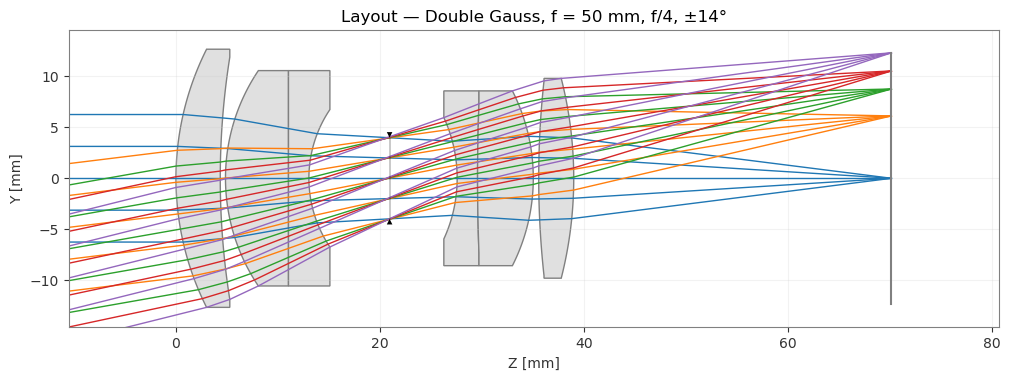

In [8]:
lens.draw(num_rays=5, figsize=(12, 4))
plt.title("Layout — Double Gauss, f = 50 mm, f/4, ±14°")
plt.show()

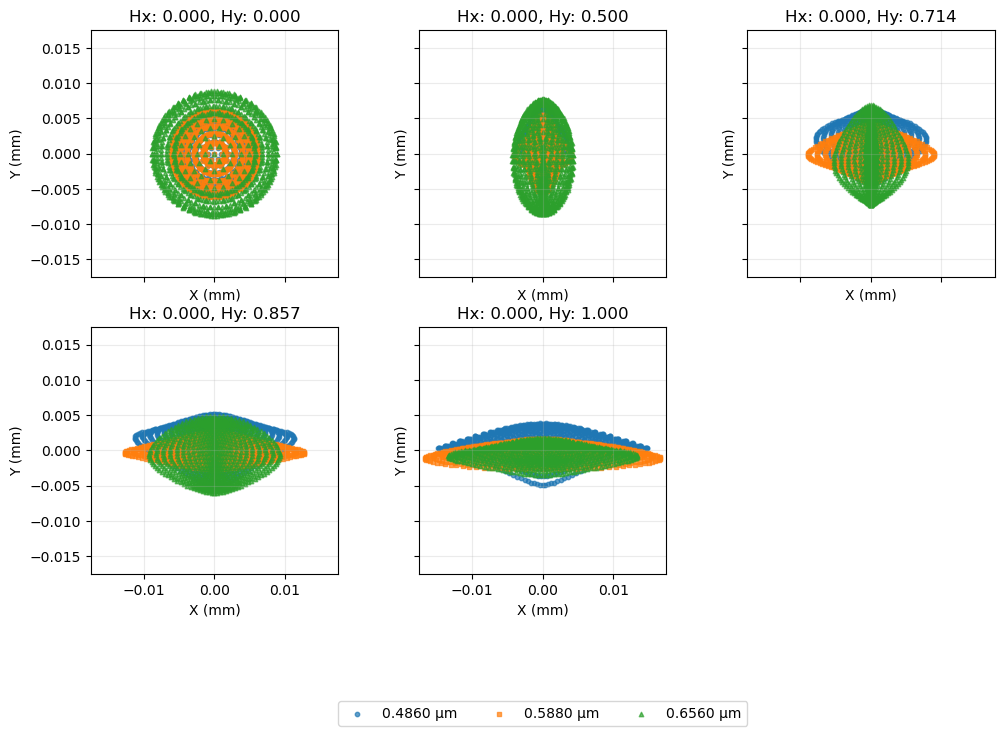

In [9]:
spot = SpotDiagram(lens, num_rings=16, reference="centroid")
spot.view()
plt.show()

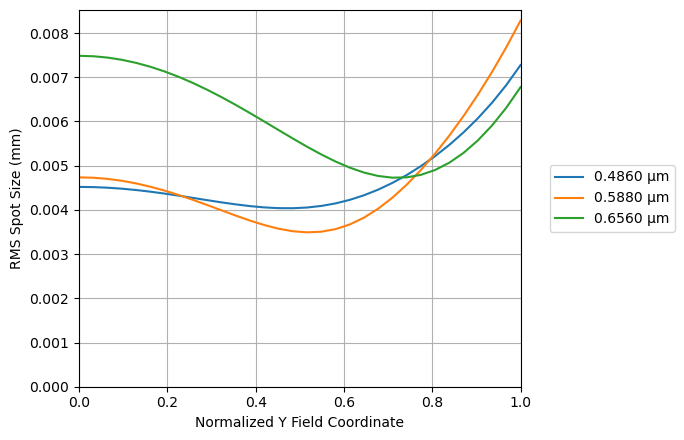

In [10]:
RmsSpotSizeVsField(lens, num_fields=32, num_rings=16).view()
plt.show()

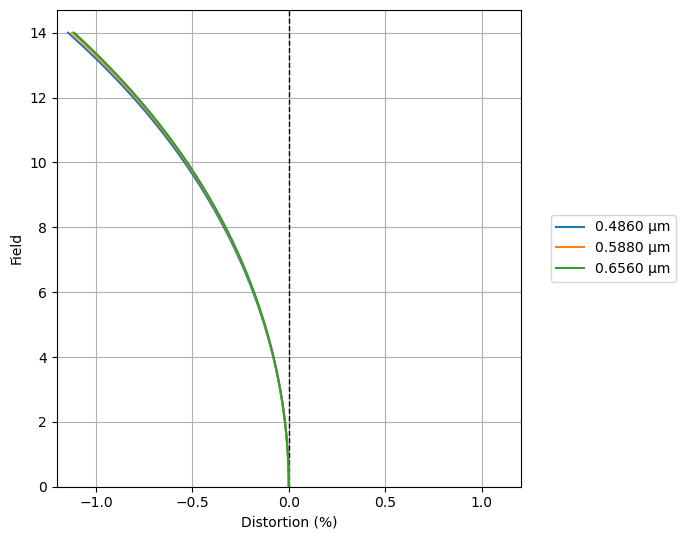

In [11]:
Distortion(lens).view()
plt.show()

## 6. How the design was obtained 

* **Start:** Optiland's `DoubleGauss` sample (f = 100 mm, f/5, ±14°, 6 elements, two cemented doublets, stop in the central air space), changed to f = 50 mm and set to f/4. The two flints (1.9 mm after scaling) were brought to the 2 mm minimum; the flat cemented interfaces were given a large finite radius so they could bend.
* **Variables:** all radii except the flat stop surface (10), all center thicknesses (≥ 2 mm), all air spaces, and the BFD (≥ 10 mm).
* **Merit:** polychromatic RMS spot at the 5 fields + every term of P (with a small safety margin on the limits), plus a smooth EFL = 50 mm target.
* **Optimiser:** Optiland `LeastSquares` (damped least squares, `trf`)


Glass sets tried:

| Glasses (outer crown / inner crown / flint / rear crown) | Mean RMS (6-ring sampling) |
|---|---|
| **N-SSK2 / N-SK2 / F5 / N-SK16** (original sample glasses) | **5.6 µm** |
| N-LAK22 / N-LAK22 / N-SF5 / N-LAK22 | 7.4 µm |

Other layouts optimised with the same merit function and optimiser (all with P = 0):

| Layout | Elements | Mean polychromatic RMS | Score Σ RMS² + P [mm²] |
|---|---|---|---|
| Cooke triplet (N-LAK22 / N-SF5) | 3 | 10.31 µm | 6.11 × 10⁻⁴ |
| Triplet with split front crown (N-LAK22 / N-SF5) | 4 | 11.17 µm | 6.72 × 10⁻⁴ |
| **Double Gauss (this design)** | **6** | **5.52 µm** | **1.58 × 10⁻⁴** |

The near-symmetric Double Gauss cancels coma, distortion and lateral colour around the stop, which halves the RMS at the edge of the field compared with the triplet.

The optimisation takes ~32 min, so it is switched off by default. Set `RUN_OPTIMIZATION = True` to re-run it from the scaled sample.

In [12]:
RUN_OPTIMIZATION = False

import inspect
from optiland import optimization
from optiland.optimization.operand import operand_registry

MARGIN = {"efl": 0.004, "fno": 0.01, "bfd": 0.2, "ttl": 0.5, "dist": 0.1, "et": 0.05}
FIELD_IDX = list(range(len(FIELDS_DEG)))


def build_start_double_gauss():
    # Optiland DoubleGauss sample scaled by 0.5 (f = 50 mm), f/4, flints raised to 2 mm
    t = Optic(name="Double Gauss start")
    g = lambda name: (name, "schott")
    t.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
    t.surfaces.add(index=1, radius=28.10119, thickness=4.375, material=g("N-SSK2"))
    t.surfaces.add(index=2, radius=76.14290, thickness=0.5)
    t.surfaces.add(index=3, radius=18.84131, thickness=6.25, material=g("N-SK2"))
    t.surfaces.add(index=4, radius=1000.0, thickness=2.0, material=g("F5"))
    t.surfaces.add(index=5, radius=12.11565, thickness=8.184723)
    t.surfaces.add(index=6, radius=np.inf, thickness=6.873979, is_stop=True)
    t.surfaces.add(index=7, radius=-14.18866, thickness=2.0, material=g("F5"))
    t.surfaces.add(index=8, radius=-1000.0, thickness=5.5, material=g("N-SK16"))
    t.surfaces.add(index=9, radius=-18.96273, thickness=0.5)
    t.surfaces.add(index=10, radius=88.70588, thickness=3.5, material=g("N-SK16"))
    t.surfaces.add(index=11, radius=-39.70572, thickness=30.743768)
    t.surfaces.add(index=12)
    t.set_aperture(aperture_type="imageFNO", value=FNO_TARGET)
    t.fields.set_type("angle")
    for fy in FIELDS_DEG:
        t.fields.add(y=fy)
    for wl in WAVELENGTHS:
        t.wavelengths.add(value=wl, is_primary=(wl == PRIMARY_WL))
    return t


# Custom operands: polychromatic RMS at one field, and one P-term per rule
operand_registry.register("poly_rms_spot",
                          lambda optic, k: float(spot_sizes(optic, rings=6)[k]), overwrite=True)
operand_registry.register("constraint",
                          lambda optic, name: violations(optic, MARGIN)[name], overwrite=True)

# Older SciPy (< 1.16) does not accept `callback` in least_squares; drop it if needed,
# and let SciPy scale the variables from the Jacobian.
from optiland.optimization.optimizer.scipy import least_squares as _lsq_module
from scipy import optimize as _scipy_optimize
from types import SimpleNamespace
_accepts_cb = "callback" in inspect.signature(_scipy_optimize.least_squares).parameters

def _least_squares(*args, callback=None, **kwargs):
    if _accepts_cb:
        kwargs["callback"] = callback
    return _scipy_optimize.least_squares(*args, x_scale="jac", **kwargs)

_lsq_module.optimize = SimpleNamespace(least_squares=_least_squares)


def optimise(t, max_blocks=12, nfev_per_block=25, rel_tol=5e-3):
    problem = optimization.OptimizationProblem()
    for k in FIELD_IDX:
        problem.add_operand("poly_rms_spot", target=0.0, weight=1.0, input_data={"optic": t, "k": k})
    problem.add_operand("f2", target=EFL_TARGET, weight=0.1, input_data={"optic": t})
    for name in violations(t):
        problem.add_operand("constraint", target=0.0, weight=PENALTY_WEIGHT, input_data={"optic": t, "name": name})
    n = t.surfaces.num_surfaces
    stop = t.surfaces.stop_index
    for i in range(1, n - 1):
        if i != stop:                          # the flat stop surface keeps R = inf
            problem.add_variable(t, "radius", surface_number=i)
    glass = {a for a, _ in elements(t)}
    for i in range(1, n - 2):
        lo, hi = (CT_MIN, 12.0) if i in glass else (0.5, 25.0)
        problem.add_variable(t, "thickness", surface_number=i, min_val=lo, max_val=hi)
    problem.add_variable(t, "thickness", surface_number=n - 2, min_val=BFD_MIN, max_val=60.0)

    merit = lambda: float(np.sum(spot_sizes(t, rings=6) ** 2)) + penalty(t, MARGIN)
    last = merit()
    for _ in range(max_blocks):
        optimization.LeastSquares(problem).optimize(maxiter=nfev_per_block, tol=1e-12, method_choice="trf")
        now = merit()
        print(f"  merit = {now:.4e}   mean RMS = {spot_sizes(t, rings=6).mean() * 1e3:.2f} um")
        if last - now < rel_tol * last:
            break
        last = now
    return t


if RUN_OPTIMIZATION:
    optimised = optimise(build_start_double_gauss())
    print("Mean polychromatic RMS:", spot_sizes(optimised).mean() * 1e3, "um   P =", penalty(optimised))
else:
    print("Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.")

Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.
